In [1]:
import numpy as np
from matplotlib import pyplot as plt
from scipy import stats
from sklearn.linear_model import LinearRegression

# np.random.seed(42)

# Лінійна регресія

## А. Генерування фіч (регресорів, x)

Згенеруйте вибірку регресорів об'єму n=100 відповідно до варіанту

2. U[-5, 5]


In [3]:
n = 100
x = np.random.uniform(-5, 5, size=n)

print(f"min x: {x.min():.4f}, max x: {x.max():.4f}, ave x: {x.mean():.4f}")

min x: -4.9659, max x: 4.9714, ave x: 0.2243


## Б. Генерація похибок $\varepsilon_i$

Згенеруйте n=100 похибок відповідно до варіантів

2. U[-0.25, 0.2]

In [8]:
eps = np.random.uniform(-0.25, 0.2, size=n)

print(f"eps: {np.round(eps[:10], 4)}")
print(f"Вибіркове середнє похибок: {eps.mean():.4f} (теоретичне E[eps] = {(-0.25 + 0.2) / 2:.4f})")

eps: [ 0.0726 -0.1749  0.0799 -0.024  -0.1358  0.0996 -0.0543  0.0501  0.1747
  0.05  ]
Вибіркове середнє похибок: -0.0101 (теоретичне E[eps] = -0.0250)


## В. Побудуйте таргети (відгуки, у) за наступною моделлю регресії

$$y_i = \theta_0 + x_i \theta_1 + \varepsilon_i$$
де $\theta=(0.5, -0.5)$, $1\leq i\leq n$

In [9]:
theta = np.array([0.5, -0.5])
y = theta[0] + theta[1] * x + eps

print(f"y: {np.round(y[:10], 4)}")

y: [ 0.7962 -1.2873  0.9976  0.3805 -0.7765  3.0364  2.532  -1.0166 -1.0697
  0.4932]


## Г. Exploratory data analysis
- зобразіть окремо гістограми $x$ та $y$

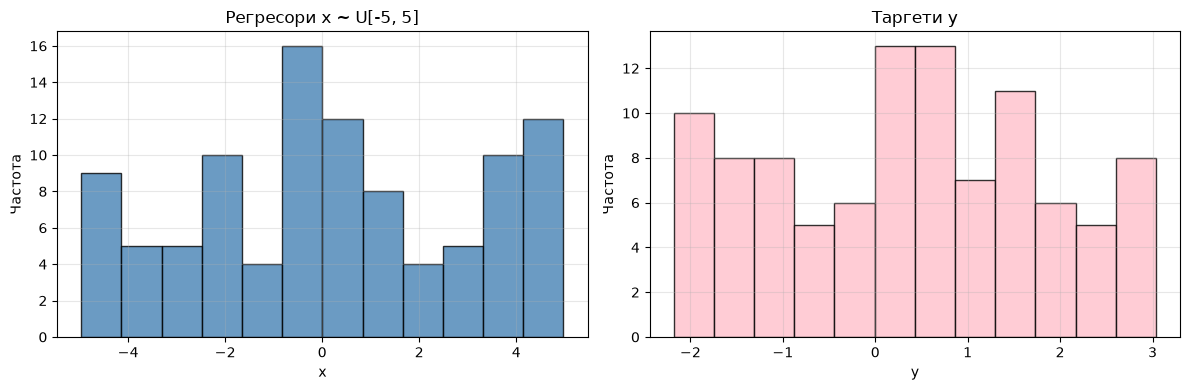

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].hist(x, bins=12, color='steelblue', edgecolor='black', alpha=0.8)
axes[0].set_title('Регресори x ~ U[-5, 5]')
axes[0].set_xlabel('x')
axes[0].set_ylabel('Частота')
axes[0].grid(alpha=0.3)

axes[1].hist(y, bins=12, color='pink', edgecolor='black', alpha=0.8)
axes[1].set_title('Таргети y')
axes[1].set_xlabel('y')
axes[1].set_ylabel('Частота')
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

- Зобразіть діаграму розсіювання пар $x, y$

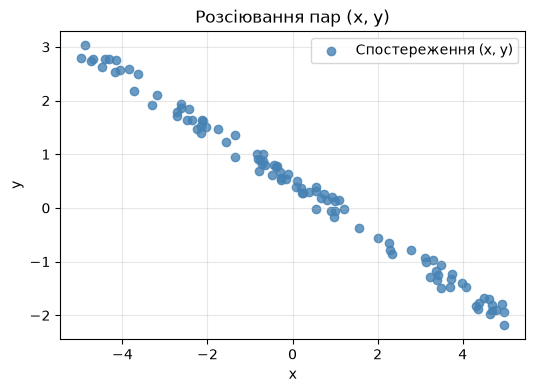

In [21]:
plt.figure(figsize=(6, 4))
plt.scatter(x, y, color='steelblue', alpha=0.8, label='Спостереження (x, y)')
plt.title('Розсіювання пар (x, y)')
plt.xlabel('x')
plt.ylabel('y')
plt.grid(alpha=0.3)
plt.legend()
plt.show()

- Чи має місце лінійна залежність
- Так, на діаграмі розсіювання помітна сильна спадна лінійна залежність між $x$ та $y$

4. Порахуйте кореляцію спірмена (коефіцієнт лінійної кореляції)

In [23]:
pearson_corr = np.corrcoef(x, y)[0, 1]
spearman_corr, spearman_pval = stats.spearmanr(x, y)

print(f"Коеф кореляції Пірсона r(x, y):     {pearson_corr:.6f}")
print(f"Коеф кореляції Спірмена rho(x, y): {spearman_corr:.6f} (p-value = {spearman_pval:.2e})")

Коеф кореляції Пірсона r(x, y):     -0.996465
Коеф кореляції Спірмена rho(x, y): -0.994611 (p-value = 2.77e-98)


## Д. Оцінка параметрів моделі за МНК
- оцініть параметри моделі за МНК, порахуйте значення функціоналу МНК

In [26]:
# Аналітичний розрахунок МНК
X = np.array([[1] * n, x]).T
theta_est = np.linalg.inv(X.T.dot(X)).dot(X.T.dot(y))

# Розрахунок через LinearRegression
model = LinearRegression().fit(x[:, None], y)
theta_sklearn = np.array([model.intercept_, model.coef_[0]])

# Predict
y_pred = model.predict(x[:, None])

rss = np.sum((y - y_pred) ** 2)
mse = np.mean((y - y_pred) ** 2)

print(f"Справжні параметри theta:      {theta}")
print(f"Оцінка МНК (аналітична):       {theta_est}")
print(f"Оцінка МНК (LinearRegression): {theta_sklearn}")
print(f"Значення функціоналу МНК (RSS = sum(y - y_pred)^2): {rss:.6f}")
print(f"Середнє значення функціоналу МНК (MSE):             {mse:.6f}")

Справжні параметри theta:      [ 0.5 -0.5]
Оцінка МНК (аналітична):       [ 0.49000988 -0.50034116]
Оцінка МНК (LinearRegression): [ 0.49000988 -0.50034116]
Значення функціоналу МНК (RSS = sum(y - y_pred)^2): 1.463761
Середнє значення функціоналу МНК (MSE):             0.014638


- Зробіть передбачення
- Зобразіть передбачення разом із таргетами

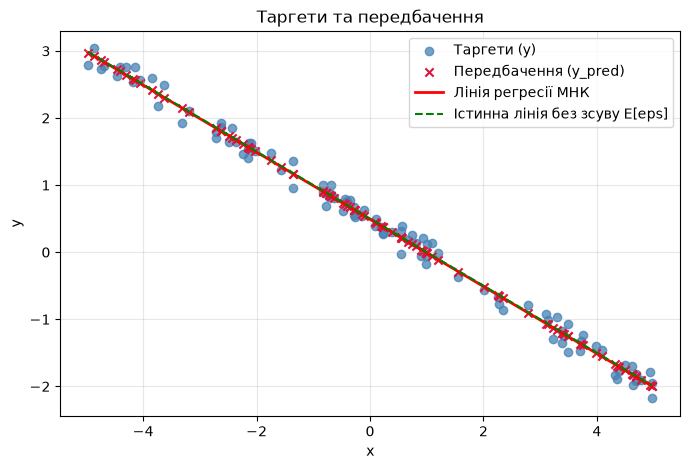

In [29]:
plt.figure(figsize=(8, 5))
plt.scatter(x, y, color='steelblue', alpha=0.75, label='Таргети (y)')
plt.scatter(x, y_pred, color='crimson', marker='x', s=35, label='Передбачення (y_pred)')

t = np.array([x.min(), x.max()])
plt.plot(t, model.predict(t[:, None]), color='red', linewidth=2, label='Лінія регресії МНК')
plt.plot(t, theta[0] + theta[1] * t, color='green', linestyle='--', linewidth=1.5, label='Істинна лінія без зсуву E[eps]')

plt.title('Таргети та передбачення')
plt.xlabel('x')
plt.ylabel('y')
plt.grid(alpha=0.3)
plt.legend()
plt.show()

- Зобразіть гістограму залишків (передбачення - таргети)

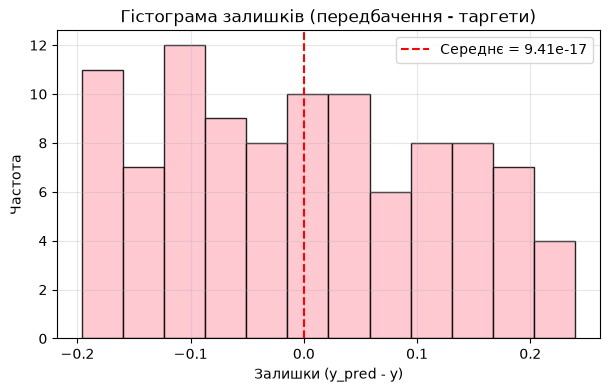

In [31]:
residuals = y_pred - y

plt.figure(figsize=(7, 4))
plt.hist(residuals, bins=12, color='pink', edgecolor='black', alpha=0.85)
plt.axvline(residuals.mean(), color='red', linestyle='--', linewidth=1.5, label=f'Середнє = {residuals.mean():.2e}')
plt.title('Гістограма залишків (передбачення - таргети)')
plt.xlabel('Залишки (y_pred - y)')
plt.ylabel('Частота')
plt.grid(alpha=0.3)
plt.legend()
plt.show()

5. Яким є середнє відхилення?

Порахуємо як середнє арифметичне залишків $\bar{e} = \frac{1}{n}\sum_{i=1}^n (\hat{y}_i - y_i)$, так і середнє абсолютне відхилення $\text{MAD} = \frac{1}{n}\sum_{i=1}^n |\hat{y}_i - y_i|$ (а також RMSE).

In [33]:
mean_residual = np.mean(residuals)
mad = np.mean(np.abs(residuals))
rmse = np.sqrt(np.mean(residuals ** 2))
s0 = np.sqrt(np.sum(residuals ** 2) / (n - 2))

print(f"Середнє значення залишків (mean(y_pred - y)): {mean_residual:.2e} (теоретично дорівнює 0)")
print(f"Середнє абсолютне відхилення (MAD):          {mad:.6f}")
print(f"Корінь середньоквадратичної похибки (RMSE):  {rmse:.6f}")
print(f"Незміщена оцінка СКВ похибки (s_0):          {s0:.6f}")

Середнє значення залишків (mean(y_pred - y)): 9.41e-17 (теоретично дорівнює 0)
Середнє абсолютне відхилення (MAD):          0.103459
Корінь середньоквадратичної похибки (RMSE):  0.120986
Незміщена оцінка СКВ похибки (s_0):          0.122214


- Порахуйте лінійну кореляцію між залишками та передбаченнями. Чи вони незалежні?

Похибки мають рівномірний розподіл і також звлишки вибірки $e_i = (\hat{\theta}_0 - \theta_0) + (\hat{\theta}_1 - \theta_1)x_i - \varepsilon_i$ залежить від $x_i$ та оцінок $\hat{\theta}_0, \hat{\theta}_1$, які обчислені за тими ж даними $(x_1, \dots, x_n)$

Лінійна кореляція Пірсона між залишками та передбаченнями: -1.01e-15


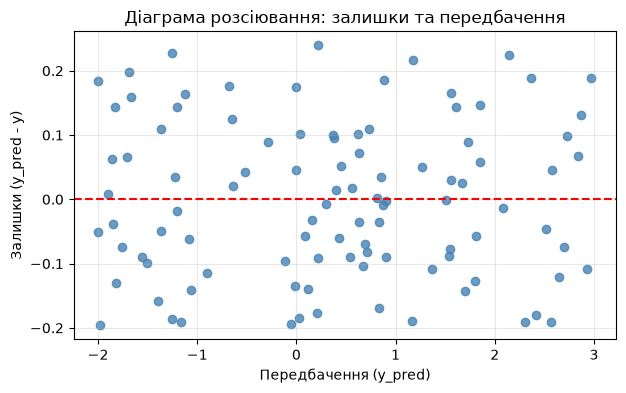

In [35]:
corr_res_pred = np.corrcoef(residuals, y_pred)[0, 1]
print(f"Лінійна кореляція Пірсона між залишками та передбаченнями: {corr_res_pred:.2e}")

plt.figure(figsize=(7, 4))
plt.scatter(y_pred, residuals, color='steelblue', alpha=0.8)
plt.axhline(0, color='red', linestyle='--')
plt.title('Діаграма розсіювання: залишки та передбачення')
plt.xlabel('Передбачення (y_pred)')
plt.ylabel('Залишки (y_pred - y)')
plt.grid(alpha=0.3)
plt.show()

- Чи вдалося гарно оцінити параметри $\theta$.  Якщо не вийшло, то яка в цьому причина?


**Висновок щодо точності оцінювання параметрів $\theta$:**
- Параметр нахилу $\theta_1 = -0.5$** оцінено дуже добре
- Вільний член $\theta_0 = 0.5$** оцінено зі систематичним зміщенням (зсувом) вниз: $\hat{\theta}_0 \approx 0.4736$ замість $0.5$.
